
# CS156 Session 11: Data Ethics and the Bias-Variance Trade-off

**Session focus:** Understanding how model complexity affects predictions and how data collection can create statistical and ethical problems.

In this notebook, I explain the key ideas from the readings and my pre-class work. I then use the Ames housing dataset to train a linear regression model, evaluate its predictions, and compare house prices across neighborhoods.

I keep the code separate from my interpretation so that each step has a clear purpose.

## Assigned Readings

1. Mehrotra — *Human Touch*
2. Wilber and Werness — *The Bias Variance Tradeoff*
3. Cornell — *Bias-Variance Tradeoff*
4. Federal Data Strategy — *Data Ethics Framework*



# Question 1 of 6: Basic Questions for Class

## What is the bias-variance trade-off?

The bias-variance trade-off is about balancing a model's complexity. A simple model may miss important patterns, leading to **high bias (underfitting)**. A complex model may learn noise from the training data, leading to **high variance (overfitting)**.

This is a dilemma because reducing bias may increase variance, and reducing variance may increase bias. The goal is to find a model that learns useful patterns and performs well on new data.

For squared-error regression, the expected test error can be written as:

$$
\mathbb{E}[(\hat{f}_D(X)-Y)^2]
=
\mathrm{Bias}^2+\mathrm{Variance}+\mathrm{Noise}
$$

- **Bias:** How far the model's average prediction is from the true expected value.
- **Variance:** How much predictions change when the model is trained on different datasets.
- **Noise:** Variation in outcomes that the available features cannot explain.

## How is statistical bias different from everyday bias?

Statistical bias refers to systematic errors in a model's predictions. For example, a linear model might consistently make incorrect predictions when the actual relationship is curved.

In everyday language, bias usually means unfairly favoring or disadvantaging certain people or groups. For example, a hiring process might favor men over women.

The main difference is that statistical bias concerns prediction errors, while social bias concerns unfair treatment. They can overlap, but they are not the same.

## Related Questions About Data Ethics

### Statistical Bias Versus Algorithmic Fairness

Statistical bias measures prediction error, while algorithmic fairness considers whether a model treats different people or groups fairly.

A model could have low statistical bias but still produce unfair outcomes. For example, a hiring model might accurately reproduce historical hiring decisions, even if those decisions were discriminatory.

### Representative Samples Versus Biased Samples

A representative sample reflects the population we want to study. A biased sample overrepresents or underrepresents certain groups.

Even a large dataset might not represent the target population properly. As a result, the model could perform well for some groups but poorly for others.

### Correlation Versus Causation

Correlation means two variables are statistically related, while causation means one variable directly influences another.

For example, a relationship between neighborhood and house price does not prove that the neighborhood alone causes the price difference.

## My Interpretation

Model accuracy is important, but we also need to understand where the data came from and how predictions might affect people.

A model can perform well statistically while still creating unfair outcomes.


In [1]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Loading the Ames housing data directly from GitHub
url = "https://raw.githubusercontent.com/tiwari91/Housing-Prices/master/train.csv"
df_train = pd.read_csv(url)

# Selecting the house features and sale price
features = ['GrLivArea', 'BedroomAbvGr', 'FullBath']
target = 'SalePrice'

# Removing missing values to keep the training data complete
df_clean = df_train[features + [target]].dropna()

# Separating the input features from the target
X = df_clean[features]
y = df_clean[target]

# Checking the number of observations and the first five rows
print(f"Total houses used: {len(df_clean)}")
print(df_clean.head())


Total houses used: 1460
   GrLivArea  BedroomAbvGr  FullBath  SalePrice
0       1710             3         2     208500
1       1262             3         2     181500
2       1786             3         2     223500
3       1717             3         1     140000
4       2198             4         2     250000



## Training and Testing the Linear Regression Model

### Why Am I Splitting the Dataset?

I divided the dataset into **80% training data and 20% testing data**.

The training data helps the model learn relationships between house features and sale prices.

The testing data helps me evaluate how well the model predicts prices for houses it has never seen before.

I used `random_state=42` so that the same observations are selected each time I run the code. This makes my results reproducible.

### How Will I Evaluate the Model?

I will calculate two evaluation metrics.

**Mean Absolute Error (MAE)** measures the average absolute difference between predicted and actual prices.

$$
\mathrm{MAE}
=
\frac{1}{n}
\sum_{i=1}^{n}|y_i-\hat{y}_i|
$$

**Mean Squared Error (MSE)** measures the average squared difference between predicted and actual prices.

$$
\mathrm{MSE}
=
\frac{1}{n}
\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

MSE gives more weight to larger prediction mistakes because the differences are squared.

I included both metrics because MAE is easier to interpret in dollars, while MSE helps show how strongly large errors affect the model's performance.


In [2]:

# Dividing the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Training the linear regression model on the training houses
model = LinearRegression()
model.fit(X_train, y_train)

# Predicting prices for houses excluded from training
y_pred = model.predict(X_test)

# Measuring the differences between predicted and actual prices
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

# Reporting model performance and dataset sizes
print(f"Mean Absolute Error: ${mae:,.2f}")
print(f"Mean Squared Error: {mse:,.2f}")
print(f"Training Samples: {len(X_train)}")
print(f"Testing Samples: {len(X_test)}")


Mean Absolute Error: $35,788.06
Mean Squared Error: 2,806,426,667.25
Training Samples: 1168
Testing Samples: 292



## Interpreting the Model's Performance

The model produced the following results in my pre-class work:

- **Training samples:** 1,168
- **Testing samples:** 292
- **Mean Absolute Error:** $35,788.06
- **Mean Squared Error:** 2,806,426,667.25

The MAE indicates that the predicted house prices were approximately **$35,788 away from the actual prices on average**, in absolute terms.

This is a substantial error for an individual property estimate.

The MSE is much larger numerically because it squares each prediction error. Its units are dollars squared rather than dollars.

### My Interpretation

The model can use living area, bedrooms, and bathrooms to estimate sale prices, but these features do not explain every difference between houses.

For example, houses with the same living area and number of bedrooms could have different prices because of their location, age, condition, or overall quality.

Therefore, I would not rely on this simple model alone for an important financial decision.

A more complete model could include additional features, but I would need to evaluate whether they actually improve predictions on unseen data.



## Predicting the Price of a Sample House

### What Question Am I Answering?

**What price would the model predict for a house with 1,500 square feet of living area, three bedrooms, and two full bathrooms?**

In my original pre-class work, I retrained the model using all available observations after completing the train/test evaluation.

The reason was to allow the final model to learn from more available information before making the sample prediction.

However, this does not mean I tested the final model again.

The previous MAE and MSE were calculated using the model trained on 80% of the observations.

After retraining on all the houses, the previous test records are no longer independent test data for the new model.

### Why Is This Distinction Important?

Testing measures how well a model performs on unseen observations.

Predicting uses a trained model to estimate an unknown outcome.

These are different tasks, and we should not confuse them.


In [3]:

# Retraining on all available houses after completing model evaluation
model.fit(X, y)

# Creating a sample house using actual measurements
sample_house = pd.DataFrame({
    'GrLivArea': [1500],
    'BedroomAbvGr': [3],
    'FullBath': [2]})

# Predicting the sale price of the sample house
predicted_price = model.predict(sample_house)[0]

# Reporting the sample house details and predicted price
print("Sample House Details:")
print(f"Living Area: {sample_house['GrLivArea'].iloc[0]} sq ft")
print(f"Bedrooms: {sample_house['BedroomAbvGr'].iloc[0]}")
print(f"Full Bathrooms: {sample_house['FullBath'].iloc[0]}")
print(f"Predicted Sale Price: ${predicted_price:,.2f}")


Sample House Details:
Living Area: 1500 sq ft
Bedrooms: 3
Full Bathrooms: 2
Predicted Sale Price: $188,413.45



## Interpreting the Predicted Sale Price

For a house with 1,500 square feet, three bedrooms, and two full bathrooms, the model predicted a sale price of approximately **$188,413.45**.

### How Is This Useful to the Bank?

The bank could use this prediction as an initial estimate of the property's value when reviewing mortgage applications.

However, the prediction is based on only three features. It does not consider several important factors, such as neighborhood, construction year, or overall house condition.

Therefore, this prediction should be treated as a starting estimate rather than a professional appraisal.

### My Interpretation

This exercise helped me understand how linear regression can make predictions using numerical features.

It also showed me why evaluating prediction error matters. A model can generate a reasonable-looking price, but this does not guarantee that the prediction is accurate for every house.



# Question 5 of 6: Extension — House Prices by Neighborhood

## Research Question

**How do median house sale prices differ across neighborhoods in Ames, Iowa?**

I was also interested in whether adding neighborhood information could improve our earlier house-price regression model.

However, the visualization only explores differences in prices; it does not yet test whether neighborhood improves prediction accuracy.

## Why Did I Choose This Visualization?

I grouped the houses by neighborhood and calculated the median sale price for each group.

I chose the **median** because it represents the middle sale price. Unlike the mean, it is less influenced by unusually expensive houses.

I also calculated how many houses were available in each neighborhood.

This is important because neighborhoods with fewer observations may have less reliable estimated median prices.

## What Will the Code Do?

The code will:

1. Group houses using the `Neighborhood` column.
2. Calculate the median sale price for each neighborhood.
3. Count the number of observations in each neighborhood.
4. Sort neighborhoods from the lowest to highest median price.
5. Create a horizontal bar chart to compare the results.

I will also label each bar with its sample size to make differences in data availability easier to identify.


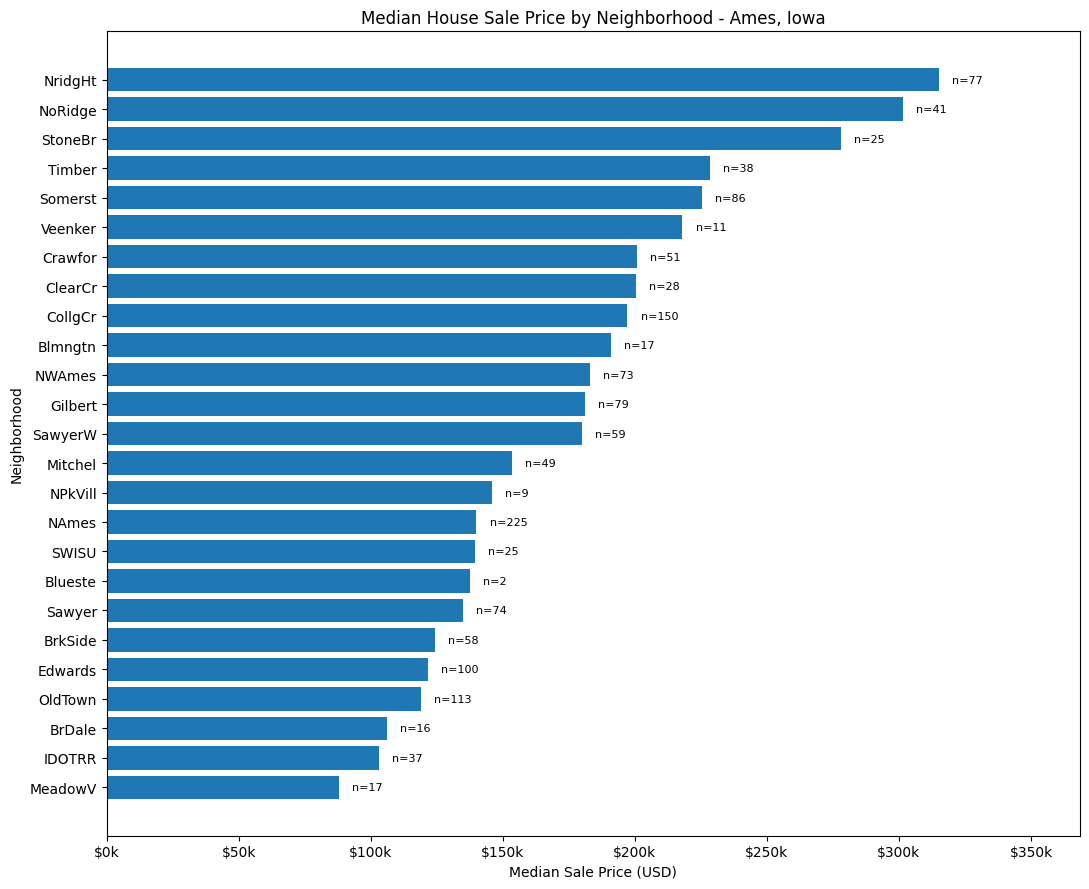

In [4]:

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Grouping houses by neighborhood and calculating the median price and sample size
neighborhood_stats = df_train.groupby('Neighborhood')['SalePrice'].agg(median='median', count='count').sort_values('median')

# Plotting the median sale price for each neighborhood
fig, ax = plt.subplots(figsize=(11, 9))
ax.barh(neighborhood_stats.index, neighborhood_stats['median'])

# Labeling each bar with the number of houses in that neighborhood
for i, (price, count) in enumerate(zip(neighborhood_stats['median'], neighborhood_stats['count'])):
    ax.text(price + 5000, i, f"n={count}", va='center', fontsize=8)

# Adding a title and axis labels to explain the visualization
ax.set_title('Median House Sale Price by Neighborhood - Ames, Iowa')
ax.set_xlabel('Median Sale Price (USD)')
ax.set_ylabel('Neighborhood')

# Setting enough space to display sample sizes next to the bars
ax.set_xlim(0, neighborhood_stats['median'].max() * 1.17)

# Formatting the price axis in thousands of dollars
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'${x/1000:,.0f}k'))

# Adjusting the layout and displaying the figure
plt.tight_layout()
plt.show()



## What Patterns Do I Notice?

The visualization shows clear differences in median house sale prices across neighborhoods in Ames, Iowa.

### Neighborhoods With Higher Prices

Northridge Heights (`NridgHt`) has the highest median sale price at approximately **$315,000**.

Northridge (`NoRidge`) follows at approximately **$301,500**.

### Neighborhoods With Lower Prices

Meadow Village (`MeadowV`) has one of the lowest median sale prices at approximately **$88,000**.

### Differences Between Neighborhoods

The highest neighborhood median is more than three times the lowest.

This suggests that location is associated with differences in house sale prices.

However, the chart also shows differences in sample size. Some neighborhoods have very few houses, making their estimated medians less reliable.

## My Interpretation

Neighborhood appears to provide useful information about house prices.

However, this relationship does not necessarily mean that location itself causes higher or lower prices.

For example, neighborhoods may differ in average house size, age, construction quality, or available amenities.

Therefore, I would want to examine these other factors before drawing conclusions.

## How Does This Connect to Our Earlier Model?

Our original linear regression model only used living area, bedrooms, and bathrooms.

A useful next step would be to compare two models:

- **Model 1:** Living area, bedrooms, and bathrooms.
- **Model 2:** Living area, bedrooms, bathrooms, and neighborhood.

I could then compare their test errors to see whether including neighborhood improves prediction accuracy.

This would help answer whether neighborhood provides useful information beyond the other house features.

## Ethical Considerations

Using neighborhood information could also create fairness concerns, especially if the model influences lending decisions.

Historical inequalities might be reflected in property values. A model could reproduce these patterns without understanding the social conditions behind them.

Therefore, I would need to evaluate both predictive accuracy and potential unfair outcomes.

**Correlation does not imply causation.**



# Final Reflection: Connecting Model Performance and Data Ethics

This session helped me understand that machine learning is not only about training models and minimizing prediction error.

We also need to understand how the data were collected, whether our models generalize to new observations, and how their predictions may affect people.

Through the housing dataset, I learned how to train a linear regression model, evaluate it using unseen data, and interpret its prediction errors.

The neighborhood analysis also showed that location is associated with differences in house prices. However, I cannot conclude that location itself causes these differences without further investigation.

The ethics readings helped me understand why this distinction matters. A model could identify statistically useful patterns while still reinforcing existing inequalities.

## Main Takeaways

- **Model performance:** Evaluate models on unseen data rather than relying only on training accuracy.
- **Bias and variance:** Understand whether poor predictions come from a model being too simple or too sensitive to training data.
- **Data collection:** Consider how sampling decisions and missing information affect results.
- **Data ethics:** Evaluate privacy, fairness, transparency, and accountability before using predictions in important decisions.

My main takeaway is that a technically accurate model is not automatically an ethical model. Both statistical performance and social consequences should guide how we develop and use machine learning systems.

## Dataset

Kaggle: https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data

Public CSV: https://github.com/tiwari91/Housing-Prices/blob/master/train.csv
